# Intraday BTC/USDT Exploration

Week 1 goal: inspect processed 5-minute OHLCV data before modeling.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data/processed/btcusdt_5m.parquet"

df = pd.read_parquet(DATA_PATH)
df.head()

,open,high,low,close,volume,return,log_return
timestamp,,,,,,,
2024-01-01 00:00:00+00:00,42283.58,42397.23,42261.02,42397.23,155.257,NaN,NaN
2024-01-01 00:05:00+00:00,42397.22,42432.74,42385.26,42409.96,141.311,0.000300,0.000300
2024-01-01 00:10:00+00:00,42409.97,42488.09,42409.96,42488.00,135.143,0.001840,0.001838
2024-01-01 00:15:00+00:00,42488.00,42554.57,42458.58,42458.85,163.324,-0.000686,-0.000686
2024-01-01 00:20:00+00:00,42458.85,42491.10,42445.84,42473.93,117.272,0.000355,0.000355


In [2]:
price_cols = ['open', 'high', 'low', 'close']
volume_cols = ['volume']

print(f'Shape: {df.shape}')
print(f'Start timestamp: {df.index[0]}')
print(f'End timestamp:   {df.index[-1]}')
display(df[price_cols + volume_cols].describe().T)

Shape: (105408, 7)
Start timestamp: 2024-01-01 00:00:00+00:00
End timestamp:   2024-12-31 23:55:00+00:00


,count,mean,std,min,25%,50%,75%,max
open,105408.0,65895.952959,14679.865057,38584.330,59017.6750,64211.1250,69063.5550,108258.38
high,105408.0,65960.143331,14695.748783,38657.440,59075.6000,64270.0000,69117.8275,108353.00
low,105408.0,65829.721046,14663.388786,38555.000,58954.0000,64148.7950,69000.0000,107917.54
close,105408.0,65896.438936,14679.932939,38584.330,59017.8025,64211.2100,69063.9650,108258.39
volume,105408.0,122.676761,163.304667,2.166,41.5370,75.1815,141.6750,5471.44


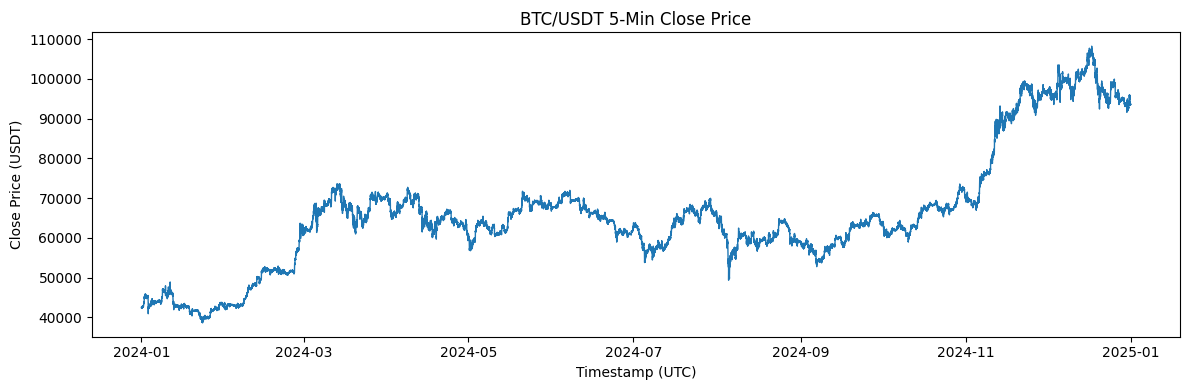

In [3]:
plt.figure(figsize=(12, 4))
plt.plot(df.index, df['close'], linewidth=1)
plt.title('BTC/USDT 5-Min Close Price')
plt.xlabel('Timestamp (UTC)')
plt.ylabel('Close Price (USDT)')
plt.tight_layout()
plt.show()

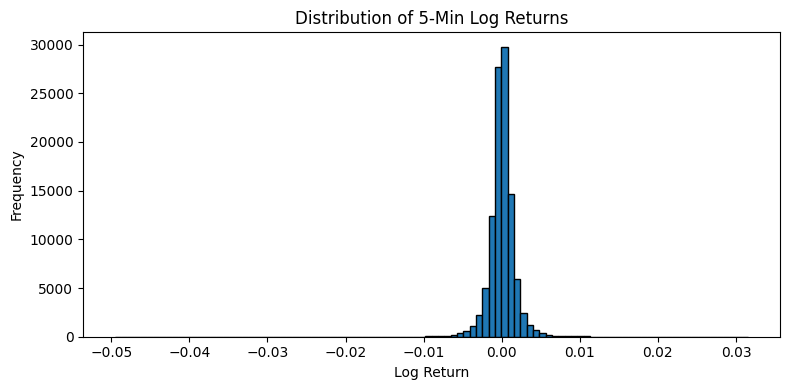

In [4]:
log_returns = df['log_return'].dropna()

plt.figure(figsize=(8, 4))
plt.hist(log_returns, bins=100, edgecolor='black')
plt.title('Distribution of 5-Min Log Returns')
plt.xlabel('Log Return')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

In [5]:
for lag in (1, 2, 5, 10):
    autocorr = log_returns.autocorr(lag=lag)
    print(f'Log Return Autocorrelation (Lag = {lag}): {autocorr:.6f}')

Log Return Autocorrelation (Lag = 1): -0.013230
Log Return Autocorrelation (Lag = 2): -0.017867
Log Return Autocorrelation (Lag = 5): 0.000641
Log Return Autocorrelation (Lag = 10): 0.001213
